# El autoencoder determinístico y su espacio latente

Un autoencoder es una red que aprende a comprimir una imagen en unos pocos números y a reconstruirla a partir de ellos. Consta de dos partes: un **codificador** (encoder), que transforma la imagen en un vector de baja dimensión llamado **representación latente**, y un **decodificador** (decoder), que convierte ese vector de nuevo en una imagen.

En esta demo se entrena un autoencoder sobre dígitos manuscritos con un espacio latente de solo **dos dimensiones**. Esa elección permite dibujar el espacio latente en un plano y responder una pregunta central para los modelos generativos: si el decodificador sabe convertir números en imágenes, ¿basta con elegir números nuevos para generar imágenes nuevas?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
np.random.seed(0)
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", dispositivo)

Dispositivo: cpu


## Datos

Se utiliza MNIST: imágenes de 28 × 28 pixeles en escala de grises, con valores entre 0 y 1. El entrenamiento **no usa las etiquetas**: el objetivo de la red es la propia imagen de entrada. Las etiquetas se conservan únicamente para colorear las gráficas del espacio latente.

In [2]:
transformacion = transforms.ToTensor()
datos_entrenamiento = datasets.MNIST("datos", train=True, download=True, transform=transformacion)
datos_prueba = datasets.MNIST("datos", train=False, download=True, transform=transformacion)

cargador_entrenamiento = DataLoader(datos_entrenamiento, batch_size=256, shuffle=True)
cargador_prueba = DataLoader(datos_prueba, batch_size=1000, shuffle=False)

print("Imágenes de entrenamiento:", len(datos_entrenamiento))
print("Imágenes de prueba:", len(datos_prueba))

Imágenes de entrenamiento: 60000
Imágenes de prueba: 10000


## Arquitectura

El codificador reduce los 784 pixeles a 2 números mediante capas densas; el decodificador es su espejo y termina en una sigmoide para producir valores entre 0 y 1. El **cuello de botella** es lo que obliga a la red a aprender algo útil: si el espacio latente tuviera tantas dimensiones como la imagen, la red podría limitarse a copiarla.

In [3]:
DIMENSION_LATENTE = 2


class Autoencoder(nn.Module):
    def __init__(self, dimension_latente):
        super().__init__()
        self.codificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512), nn.ReLU(),
            nn.Linear(512, 128), nn.ReLU(),
            nn.Linear(128, dimension_latente),
        )
        self.decodificador = nn.Sequential(
            nn.Linear(dimension_latente, 128), nn.ReLU(),
            nn.Linear(128, 512), nn.ReLU(),
            nn.Linear(512, 28 * 28), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),
        )

    def forward(self, x):
        z = self.codificador(x)
        return self.decodificador(z)


modelo = Autoencoder(DIMENSION_LATENTE).to(dispositivo)
num_parametros = sum(p.numel() for p in modelo.parameters())
print(f"Parámetros entrenables: {num_parametros:,}")

Parámetros entrenables: 936,466


## Entrenamiento

La pérdida es el **error de reconstrucción**: el error cuadrático medio entre la imagen de entrada y la imagen reconstruida. Es la única señal que recibe la red; nada en ella indica cómo debe organizarse el espacio latente.

Época  1: pérdida = 0.0634


Época  2: pérdida = 0.0485


Época  3: pérdida = 0.0446


Época  4: pérdida = 0.0428


Época  5: pérdida = 0.0415


Época  6: pérdida = 0.0406


... (5 outputs left out)

Época 12: pérdida = 0.0377


Época 13: pérdida = 0.0374


Época 14: pérdida = 0.0371


Época 15: pérdida = 0.0369


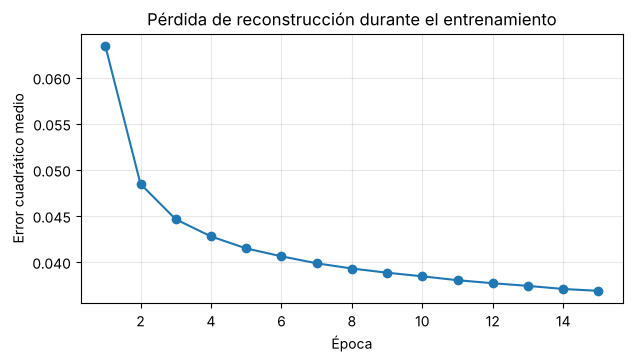

In [4]:
EPOCAS = 15
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
funcion_perdida = nn.MSELoss()
historial_perdida = []

for epoca in range(EPOCAS):
    modelo.train()
    perdida_acumulada = 0.0
    for imagenes, _ in cargador_entrenamiento:
        imagenes = imagenes.to(dispositivo)
        reconstrucciones = modelo(imagenes)
        perdida = funcion_perdida(reconstrucciones, imagenes)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        perdida_acumulada += perdida.item() * imagenes.size(0)
    historial_perdida.append(perdida_acumulada / len(datos_entrenamiento))
    print(f"Época {epoca + 1:2d}: pérdida = {historial_perdida[-1]:.4f}")

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, EPOCAS + 1), historial_perdida, marker="o")
plt.xlabel("Época")
plt.ylabel("Error cuadrático medio")
plt.title("Pérdida de reconstrucción durante el entrenamiento")
plt.grid(alpha=0.3)
plt.show()

## Reconstrucción

La fila superior muestra imágenes de prueba que la red nunca vio; la inferior, su reconstrucción a partir de solo dos números. Las reconstrucciones conservan la forma general del dígito pero pierden detalle: dos números no alcanzan para describir cada trazo.

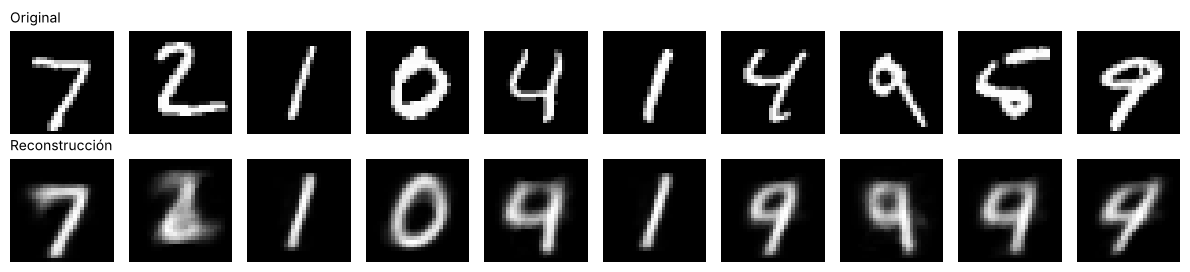

In [5]:
modelo.eval()
imagenes_prueba, etiquetas_prueba = next(iter(cargador_prueba))
with torch.no_grad():
    reconstrucciones = modelo(imagenes_prueba.to(dispositivo)).cpu()

fig, ejes = plt.subplots(2, 10, figsize=(12, 2.8))
for i in range(10):
    ejes[0, i].imshow(imagenes_prueba[i, 0], cmap="gray")
    ejes[1, i].imshow(reconstrucciones[i, 0], cmap="gray")
    ejes[0, i].axis("off")
    ejes[1, i].axis("off")
ejes[0, 0].set_title("Original", loc="left", fontsize=10)
ejes[1, 0].set_title("Reconstrucción", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## El espacio latente

Cada imagen de prueba se convierte en un punto del plano latente, coloreado según el dígito que representa. Aunque la red nunca recibió etiquetas, los dígitos similares quedan agrupados: el codificador aprendió una representación con significado.

Conviene observar también la **forma** del espacio: los grupos son alargados e irregulares, algunos dígitos ocupan un área muy grande y otros (como el 1) quedan concentrados en una región diminuta, y hay amplias zonas vacías. La escala y la ubicación de los grupos no siguen ninguna distribución conocida; dependen de cómo resultó el entrenamiento.

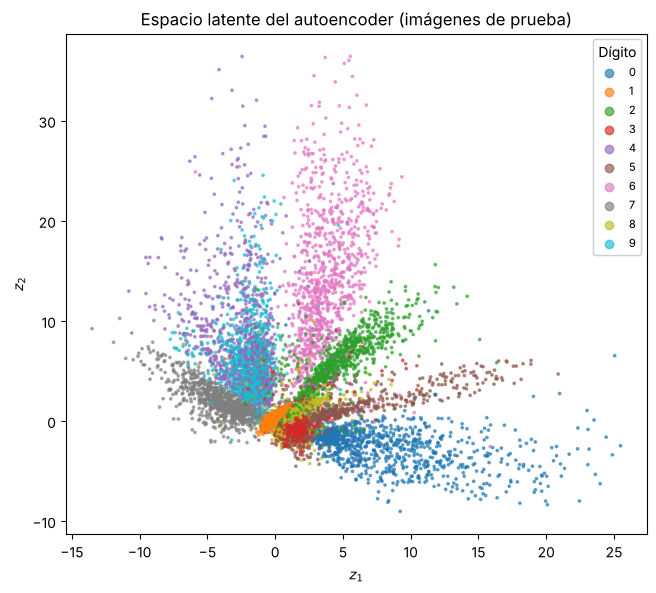

In [6]:
codigos = []
etiquetas = []
with torch.no_grad():
    for imagenes, etiquetas_lote in cargador_prueba:
        codigos.append(modelo.codificador(imagenes.to(dispositivo)).cpu())
        etiquetas.append(etiquetas_lote)
codigos = torch.cat(codigos).numpy()
etiquetas = torch.cat(etiquetas).numpy()


def graficar_espacio_latente(ax):
    dispersion = ax.scatter(codigos[:, 0], codigos[:, 1], c=etiquetas, cmap="tab10", s=3, alpha=0.6)
    ax.set_xlabel("$z_1$")
    ax.set_ylabel("$z_2$")
    return dispersion


fig, ax = plt.subplots(figsize=(7.5, 6.5))
dispersion = graficar_espacio_latente(ax)
leyenda = ax.legend(*dispersion.legend_elements(), title="Dígito", loc="best", fontsize=8)
ax.add_artist(leyenda)
ax.set_title("Espacio latente del autoencoder (imágenes de prueba)")
plt.show()

## ¿Se pueden generar imágenes eligiendo puntos nuevos?

Para generar, se toman puntos al azar dentro del rectángulo que ocupan los datos y se pasan por el decodificador. A la izquierda se marca dónde cae cada punto; a la derecha, la imagen que produce.

Al observar el resultado destacan tres problemas. Primero, los dígitos generados están muy desbalanceados: abundan los que ocupan un área grande del espacio latente y faltan los que ocupan un área pequeña. Segundo, los puntos lejanos a los datos no producen imágenes nuevas, sino copias del dígito más cercano. Tercero, los puntos que caen en la frontera entre dos grupos producen formas ambiguas que no corresponden a ningún dígito.

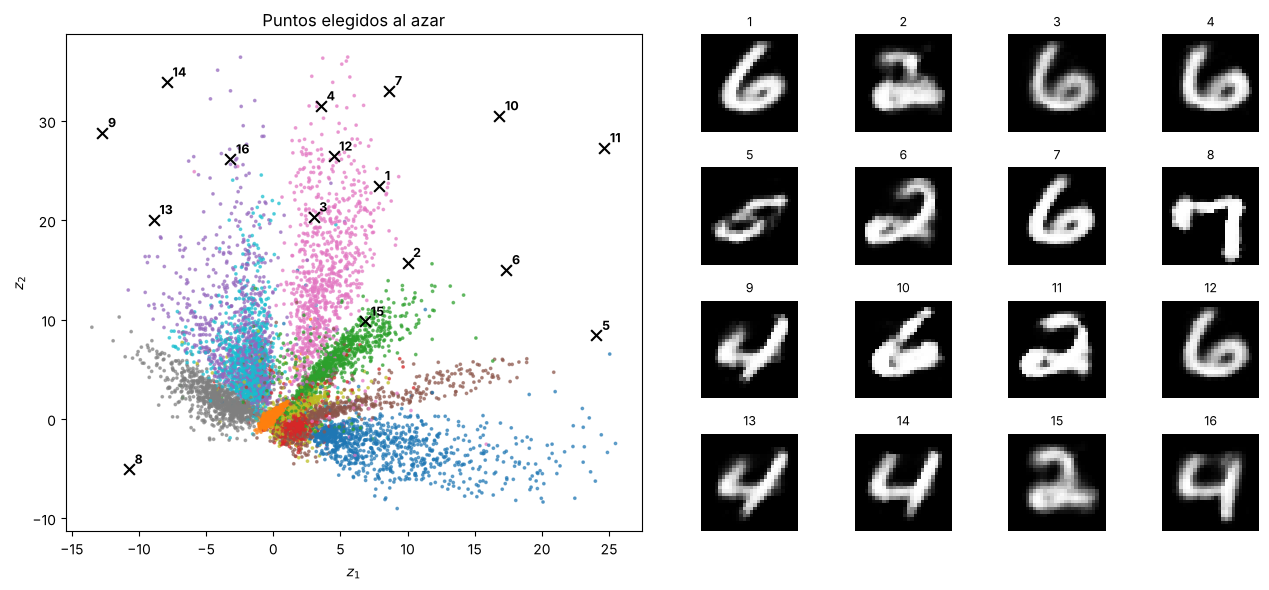

In [7]:
NUM_MUESTRAS = 16
minimos = codigos.min(axis=0)
maximos = codigos.max(axis=0)
puntos_aleatorios = np.random.uniform(minimos, maximos, size=(NUM_MUESTRAS, DIMENSION_LATENTE)).astype(np.float32)

with torch.no_grad():
    imagenes_generadas = modelo.decodificador(torch.from_numpy(puntos_aleatorios).to(dispositivo)).cpu()

fig = plt.figure(figsize=(13, 6))
ax = fig.add_subplot(1, 2, 1)
graficar_espacio_latente(ax)
ax.scatter(puntos_aleatorios[:, 0], puntos_aleatorios[:, 1], c="black", marker="x", s=60)
for i, (z1, z2) in enumerate(puntos_aleatorios):
    ax.annotate(str(i + 1), (z1, z2), xytext=(4, 4), textcoords="offset points", fontsize=9, weight="bold")
ax.set_title("Puntos elegidos al azar")

for i in range(NUM_MUESTRAS):
    ax_imagen = fig.add_subplot(4, 8, (i // 4) * 8 + 5 + i % 4)
    ax_imagen.imshow(imagenes_generadas[i, 0], cmap="gray")
    ax_imagen.set_title(str(i + 1), fontsize=9)
    ax_imagen.axis("off")
plt.tight_layout()
plt.show()

## Mapa completo del decodificador

Para ver el fenómeno en todo el plano, se decodifica una cuadrícula regular de puntos que cubre el espacio latente. Cada celda del mosaico es la imagen que el decodificador produce en esa posición. El mosaico confirma lo anterior: grandes regiones repiten el mismo dígito, las transiciones entre grupos contienen mezclas que no corresponden a ningún dígito, y algunos dígitos apenas aparecen porque ocupan una región muy pequeña del plano.

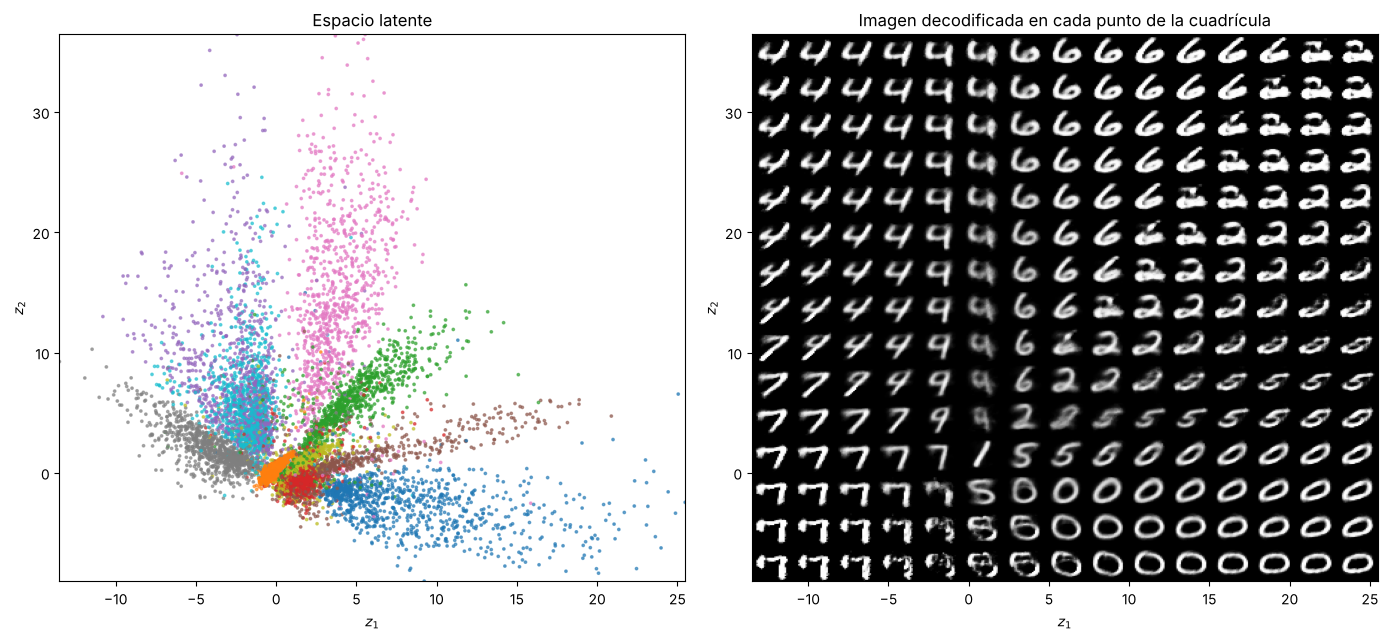

In [8]:
TAMANO_CUADRICULA = 15
valores_z1 = np.linspace(minimos[0], maximos[0], TAMANO_CUADRICULA)
valores_z2 = np.linspace(maximos[1], minimos[1], TAMANO_CUADRICULA)
cuadricula = np.array([[z1, z2] for z2 in valores_z2 for z1 in valores_z1], dtype=np.float32)

with torch.no_grad():
    mosaico = modelo.decodificador(torch.from_numpy(cuadricula).to(dispositivo)).cpu().numpy()
mosaico = mosaico.reshape(TAMANO_CUADRICULA, TAMANO_CUADRICULA, 28, 28)
mosaico = mosaico.transpose(0, 2, 1, 3).reshape(TAMANO_CUADRICULA * 28, TAMANO_CUADRICULA * 28)

fig, ejes = plt.subplots(1, 2, figsize=(14, 6.5))
graficar_espacio_latente(ejes[0])
ejes[0].set_xlim(minimos[0], maximos[0])
ejes[0].set_ylim(minimos[1], maximos[1])
ejes[0].set_title("Espacio latente")
ejes[1].imshow(mosaico, cmap="gray", extent=[minimos[0], maximos[0], minimos[1], maximos[1]], aspect="auto")
ejes[1].set_xlabel("$z_1$")
ejes[1].set_ylabel("$z_2$")
ejes[1].set_title("Imagen decodificada en cada punto de la cuadrícula")
plt.tight_layout()
plt.show()

## Conclusión

El autoencoder determinístico aprende **dónde colocar cada imagen de entrenamiento**, pero no aprende cómo se distribuyen las imágenes en general. Por eso no sirve, por sí solo, como modelo generativo: no existe una distribución conocida de la cual muestrear puntos nuevos de forma que se respeten las proporciones de los datos, y nada garantiza que un punto elegido al azar produzca una imagen válida y variada.

Para generar se necesita aprender una **distribución**, y hay dos caminos clásicos para lograrlo:

- **Ordenar el espacio latente**, obligando a que se parezca a una distribución conocida (por ejemplo, una normal estándar) para que cualquier punto muestreado de ella sea válido. Es la idea del autoencoder variacional (VAE).
- **Conservar solo el decodificador**, convertido en un generador que recibe ruido de una distribución conocida, y entrenarlo con un segundo modelo que juzga si sus imágenes parecen reales. Es la idea de las redes generativas adversarias (GANs).

La idea de comprimir imágenes en un espacio latente no desaparece: varios modelos generativos modernos, incluidos algunos de difusión, generan dentro del espacio latente de un autoencoder en lugar de hacerlo directamente sobre los pixeles.